In [7]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import os
import sys
from scipy.signal import resample_poly

These files consists of functions required to process the data

In [8]:
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [9]:
import src.data_loader
import src.preprocess_data
import src.visualisation
import src.process_data_usecases
import yaml
CONFIG_PATH = Path("../config.yaml")

In [10]:
with open(CONFIG_PATH, "r") as file:
    config = yaml.safe_load(file)

In [11]:
data_dir = Path(config["data_dir"])
dir_file = config["sessions"]
Sensor_Logger_folder = config["sensor_logger"]["folder"]

file_prefix = config["sensor_logger"]["file_prefix"]

sensor_logger_recordings_trimmed_dir = (
    Path(Sensor_Logger_folder) /
    config["sensor_logger"]["trimmed_folder"]
)

trimmed_sensor_logger_file_prefix = (
    config["sensor_logger"]["trimmed_file_prefix"]
)

 Timestamp Jitter Analysis  of Subject_1_D/Session_1
Total Samples: 76673
Ideal Interval: 10.00 ms
Mean Interval:  9.97 ms
Std Deviation:  0.52 ms
Min Interval:   9.88 ms
Max Interval:   29.83 ms
Timestamps are strictly monotonic (no backward jumps).
Detected steps: 1122


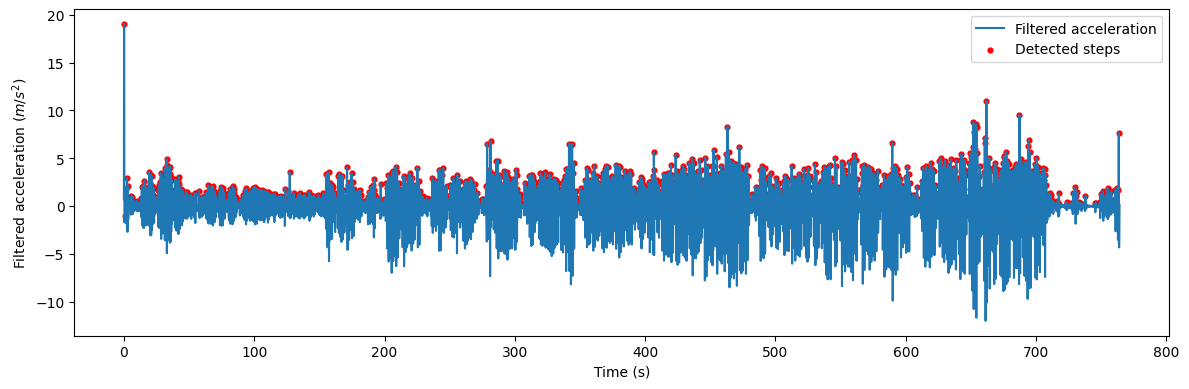

 Timestamp Jitter Analysis  of Subject_1_D/Session_2
Total Samples: 77578
Ideal Interval: 10.00 ms
Mean Interval:  9.95 ms
Std Deviation:  0.36 ms
Min Interval:   9.88 ms
Max Interval:   29.80 ms
Timestamps are strictly monotonic (no backward jumps).
Detected steps: 1184


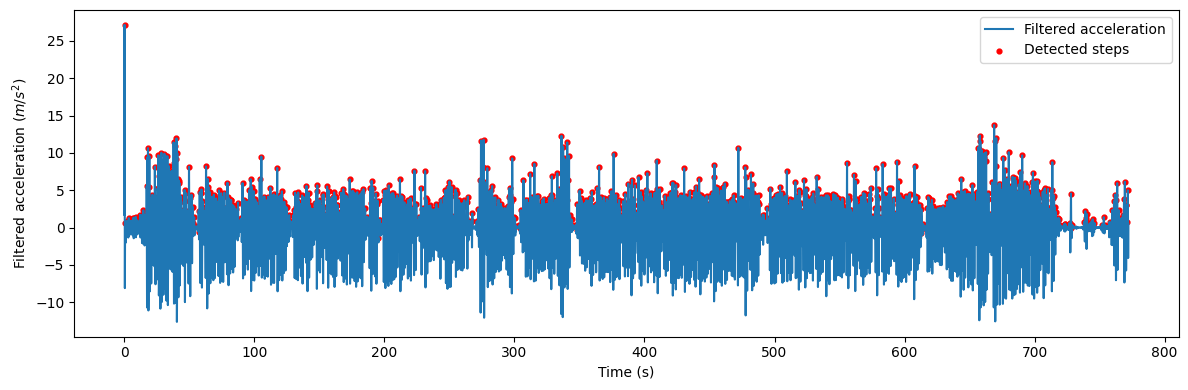

 Timestamp Jitter Analysis  of Subject_2_F/Session_1
Total Samples: 83681
Ideal Interval: 10.00 ms
Mean Interval:  9.96 ms
Std Deviation:  0.40 ms
Min Interval:   9.88 ms
Max Interval:   29.83 ms
Timestamps are strictly monotonic (no backward jumps).
Detected steps: 1213


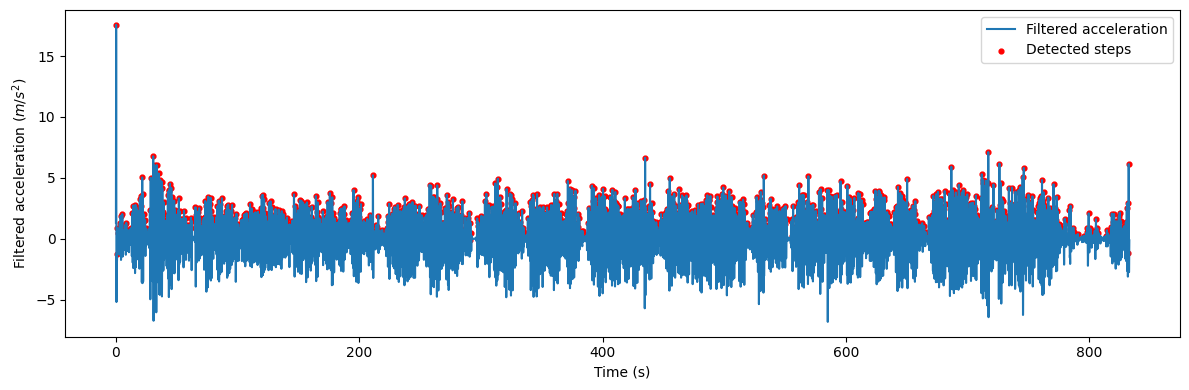

 Timestamp Jitter Analysis  of Subject_2_F/Session_2
Total Samples: 83116
Ideal Interval: 10.00 ms
Mean Interval:  9.97 ms
Std Deviation:  0.59 ms
Min Interval:   9.86 ms
Max Interval:   29.84 ms
Timestamps are strictly monotonic (no backward jumps).
Detected steps: 1214


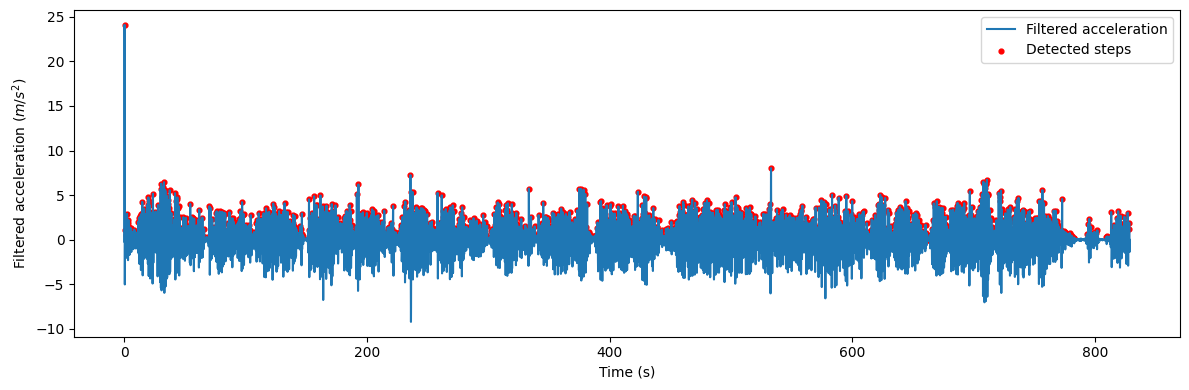

 Timestamp Jitter Analysis  of Subject_3_I/Session_2
Total Samples: 72259
Ideal Interval: 10.00 ms
Mean Interval:  9.95 ms
Std Deviation:  0.35 ms
Min Interval:   9.88 ms
Max Interval:   29.82 ms
Timestamps are strictly monotonic (no backward jumps).
Detected steps: 1155


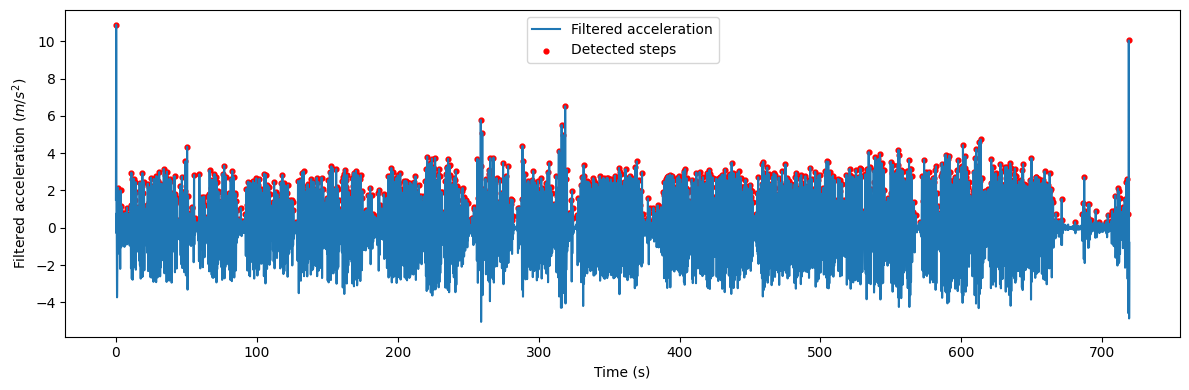

In [ ]:
for session in dir_file:
    sensor_logger_path = ( data_dir/ session/ Sensor_Logger_folder/ config["sensor_logger"]["trimmed_folder"]/ f"{trimmed_sensor_logger_file_prefix}.csv"
                          )
    sensor_logger_df = src.data_loader.load_sensor_data(sensor_logger_path, session, True)

    peaks, filtered, sensor_logger_uniform_df = src.process_data_usecases.detect_steps(sensor_logger_df, ["z", "y", "x"])

    print("Detected steps:", len(peaks))
    src.visualisation.scatterplot_stepdetection(sensor_logger_uniform_df, peaks, filtered)

In [ ]:
for session in dir_file:
    sensor_logger_path = ( data_dir/ session/ Sensor_Logger_folder/ config["sensor_logger"]["trimmed_folder"]/ f"{trimmed_sensor_logger_file_prefix}.csv")
    sensor_logger_df = src.data_loader.load_sensor_data(sensor_logger_path, session, True)

    peaks, filtered, sensor_logger_uniform_df = src.process_data_usecases.detect_steps(sensor_logger_df, ["z", "y", "x"])

    pedometer_path = ( data_dir/ session/ Sensor_Logger_folder/ config["sensor_logger"]["trimmed_folder"]/ f"trimmed_pedometer.csv"
                          )
    pedometer_df = src.data_loader.load_sensor_data(pedometer_path, None, False)
    # Sort and clean the pedometer data
    pedometer_df = (
        pedometer_df
        .sort_values("time")
        .drop_duplicates(subset="time")
        .reset_index(drop=True)
    )

    # Both time columns are assumed to be Unix timestamps in nanoseconds
    acc_ns = sensor_logger_uniform_df["time"].to_numpy(dtype=np.int64)
    ped_ns = pedometer_df["time"].to_numpy(dtype=np.int64)

    # Convert to seconds using one common time reference
    t0_ns = min(acc_ns[0], ped_ns[0])

    acc_t = (acc_ns - t0_ns) / 1e9
    ped_t = (ped_ns - t0_ns) / 1e9

    ped_steps = pedometer_df["steps"].to_numpy(dtype=np.int64)

    # Find the overlapping recording interval
    overlap_start = max(acc_t[0], ped_t[0])
    overlap_end = min(acc_t[-1], ped_t[-1])

    if overlap_end <= overlap_start:
        raise ValueError("The accelerometer and pedometer time ranges do not overlap.")

    print(f"Accelerometer duration: {acc_t[-1] - acc_t[0]:.2f} s")
    print(f"Pedometer duration:     {ped_t[-1] - ped_t[0]:.2f} s")
    print(f"Common duration:        {overlap_end - overlap_start:.2f} s")

    # Pedometer count at or immediately before the overlap starts
    baseline_idx = np.searchsorted(
        ped_t, overlap_start, side="right"
    ) - 1

    if baseline_idx < 0:
        baseline_idx = 0

    # Pedometer cumulative count, relative to the overlap start
    ped_mask = (ped_t >= overlap_start) & (ped_t <= overlap_end)

    ped_plot_t = ped_t[ped_mask] - overlap_start
    ped_cumulative = ped_steps[ped_mask] - ped_steps[baseline_idx]

    # Detected steps within the same interval
    detected_t = acc_t[peaks]
    detected_t = detected_t[
        (detected_t >= overlap_start) &
        (detected_t <= overlap_end)
    ]

    detected_plot_t = detected_t - overlap_start
    detected_cumulative = np.arange(1, len(detected_plot_t) + 1)

    # Compare the total increments
    pedometer_total = int(ped_cumulative[-1])
    detected_total = len(detected_plot_t)

    difference = detected_total - pedometer_total
    percentage_difference = (
        abs(difference) / pedometer_total * 100
        if pedometer_total != 0 else np.nan
    )

    print(f"Pedometer steps:          {pedometer_total}")
    print(f"Algorithm-detected steps: {detected_total}")
    print(f"Difference:               {difference}")
    print(f"Percentage difference:    {percentage_difference:.2f}%")

 Timestamp Jitter Analysis  of Subject_1_D/Session_1
Total Samples: 76673
Ideal Interval: 10.00 ms
Mean Interval:  9.97 ms
Std Deviation:  0.52 ms
Min Interval:   9.88 ms
Max Interval:   29.83 ms
Timestamps are strictly monotonic (no backward jumps).
Accelerometer duration: 764.08 s
Pedometer duration:     763.33 s
Common duration:        763.33 s
Pedometer steps:          1075
Algorithm-detected steps: 1121
Difference:               46
Percentage difference:    4.28%
 Timestamp Jitter Analysis  of Subject_1_D/Session_2
Total Samples: 77578
Ideal Interval: 10.00 ms
Mean Interval:  9.95 ms
Std Deviation:  0.36 ms
Min Interval:   9.88 ms
Max Interval:   29.80 ms
Timestamps are strictly monotonic (no backward jumps).
Accelerometer duration: 772.15 s
Pedometer duration:     760.73 s
Common duration:        760.73 s
Pedometer steps:          1080
Algorithm-detected steps: 1167
Difference:               87
Percentage difference:    8.06%
 Timestamp Jitter Analysis  of Subject_2_F/Session_1
T